# Détecteur de perruche à collier — YOLO26 (classification)

Objectif : entraîner un classifieur **perruche / pas_perruche**, le comparer au CNN maison,
puis l'exporter pour l'**Arduino UNO Q**.

**Avant de lancer :** active le GPU → *Exécution ▸ Modifier le type d'exécution ▸ GPU (T4)*.


## 1. Installation

In [1]:
!pip install -q ultralytics scikit-learn

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.3/41.3 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 31.3 MB/s eta 0:00:00


## 2. Charger le dataset

Deux options. **Option A** : déposer `dataset_split.zip` (bouton upload de Colab) puis dézipper.
**Option B** : monter Google Drive si le zip y est déjà.


In [2]:
# --- Option A : upload direct ---
from google.colab import files
up = files.upload()              # choisis dataset_split.zip
!unzip -q -o dataset_split.zip -d /content/

# --- Option B (à la place) : Google Drive ---
# from google.colab import drive
# drive.mount('/content/drive')
# !unzip -q -o "/content/drive/MyDrive/dataset_split.zip" -d /content/

DATA_DIR = "/content/dataset_split"   # doit contenir train/ val/ test/
!ls -R {DATA_DIR} | head -20

Saving dataset_split.zip to dataset_split.zip
/content/dataset_split:
test
train
val

/content/dataset_split/test:
pas_perruche
perruche

/content/dataset_split/test/pas_perruche:
negative_00004.jpg
negative_00027.jpg
negative_00050.jpg
negative_00065.jpg
negative_00073.jpg
negative_00078.jpg
negative_00081.jpg
negative_00104.jpg
negative_00107.jpg
negative_00110.jpg


## 3. Vérifier le GPU

In [3]:
!nvidia-smi

Wed Jun 24 20:12:37 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   40C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 4. Entraînement

On entraîne **deux tailles** :
- `yolo26n-cls` (nano) → léger, c'est lui qu'on déploiera sur l'UNO Q.
- `yolo26m-cls` (medium) → plus précis, pour le point de comparaison « meilleur YOLO ».

> Si un nom de poids échoue au téléchargement, remplace par la version 11 (très stable) :
> `yolo11n-cls.pt` / `yolo11m-cls.pt`.


In [4]:
from ultralytics import YOLO

EPOCHS = 50
IMGSZ  = 224      # tu peux descendre à 160/128 pour accélérer l'inférence sur la carte
results = {}

for tag in ["yolo26n-cls", "yolo26m-cls"]:
    print(f"\n===== Entraînement {tag} =====")
    model = YOLO(f"{tag}.pt")
    model.train(
        data=DATA_DIR,
        epochs=EPOCHS,
        imgsz=IMGSZ,
        project="/content/runs",
        name=tag,
        patience=15,      # early stopping
    )
    results[tag] = model

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.

===== Entraînement yolo26n-cls =====
Ultralytics 8.4.76 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset_split, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h

## 5. Évaluation sur le **test set**

D'abord les métriques rapides d'Ultralytics, puis une évaluation maison avec scikit-learn
(matrice de confusion + précision / rappel / F1) — les mêmes métriques à utiliser pour
comparer avec ton CNN.


In [5]:
# Métriques rapides Ultralytics sur le split test
for tag, model in results.items():
    print(f"\n--- {tag} ---")
    metrics = model.val(data=DATA_DIR, split="test")
    print("top1 accuracy :", round(float(metrics.top1), 4))


--- yolo26n-cls ---
Ultralytics 8.4.76 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n-cls summary (fused): 47 layers, 1,528,586 parameters, 0 gradients, 3.2 GFLOPs
train: /content/dataset_split/train... found 3716 images in 2 classes ✅ 
val: /content/dataset_split/val... found 797 images in 2 classes ✅ 
test: /content/dataset_split/test... found 798 images in 2 classes ✅ 
test: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4.9±2.5 MB/s, size: 5.5 KB)
test: Scanning /content/dataset_split/test... 798 images, 0 corrupt: 100% ━━━━━━━━━━━━ 798/798 1.8Kit/s 0.4s
test: New cache created: /content/dataset_split/test.cache
               classes   top1_acc   top5_acc: 100% ━━━━━━━━━━━━ 50/50 15.6it/s 3.2s
                   all      0.974          1
Speed: 0.2ms preprocess, 1.8ms inference, 0.0ms loss, 0.0ms postprocess per image
Results saved to /content/runs/classify/val
top1 accuracy : 0.9737

--- yolo26m-cls ---
Ultralytics 8.4.76 🚀 Python-3.12.13 torch-2.11.0+cu12

798 images de test

========== yolo26n-cls ==========
              precision    recall  f1-score   support

pas_perruche     0.9471    0.9908    0.9684       325
    perruche     0.9934    0.9619    0.9774       473

    accuracy                         0.9737       798
   macro avg     0.9703    0.9764    0.9729       798
weighted avg     0.9746    0.9737    0.9738       798



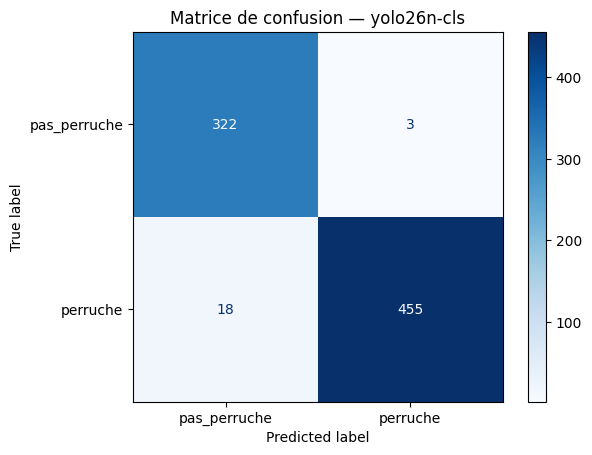


========== yolo26m-cls ==========
              precision    recall  f1-score   support

pas_perruche     0.9698    0.9877    0.9787       325
    perruche     0.9914    0.9789    0.9851       473

    accuracy                         0.9825       798
   macro avg     0.9806    0.9833    0.9819       798
weighted avg     0.9826    0.9825    0.9825       798



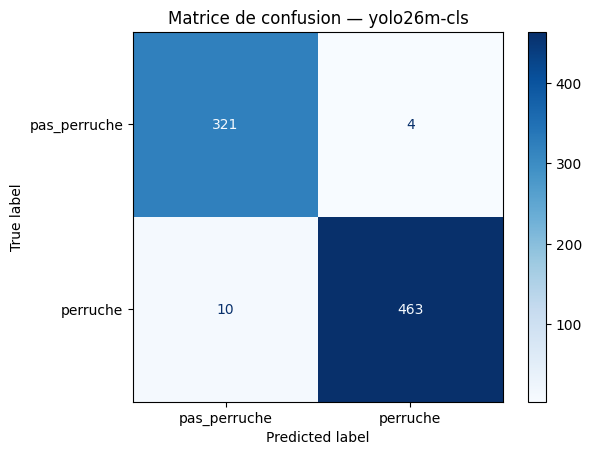

In [6]:
# Évaluation détaillée avec scikit-learn (sur le test set)
import glob, os
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

TEST_DIR = os.path.join(DATA_DIR, "test")
class_names = sorted(os.listdir(TEST_DIR))          # ['pas_perruche', 'perruche']
name_to_idx = {n: i for i, n in enumerate(class_names)}

# Liste (chemin, label_vrai)
samples = []
for cname in class_names:
    for p in glob.glob(os.path.join(TEST_DIR, cname, "*.jpg")):
        samples.append((p, name_to_idx[cname]))
paths  = [s[0] for s in samples]
y_true = np.array([s[1] for s in samples])
print(f"{len(paths)} images de test")

for tag, model in results.items():
    # Prédictions par lots
    y_pred = []
    for i in range(0, len(paths), 64):
        batch = paths[i:i+64]
        for r in model(batch, verbose=False):
            pred_name = r.names[int(r.probs.top1)]
            y_pred.append(name_to_idx[pred_name])
    y_pred = np.array(y_pred)

    print(f"\n========== {tag} ==========")
    print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

    cm = confusion_matrix(y_true, y_pred)
    ConfusionMatrixDisplay(cm, display_labels=class_names).plot(cmap="Blues", values_format="d")
    plt.title(f"Matrice de confusion — {tag}")
    plt.show()

### Comparaison avec le CNN maison

Reporte ici, pour **chaque modèle** et sur le **même test set**, les mêmes chiffres :
accuracy, précision, rappel, F1 (classe « perruche »).

> Rappel pour ton rapport : les YOLO de classification sont **pré-entraînés sur ImageNet**
> (transfer learning), alors que ton CNN part probablement de zéro. Une partie de l'écart vient
> de là, pas seulement de l'architecture — sois explicite dessus.


## 6. Export pour l'Arduino UNO Q

L'UNO Q tourne sous **Debian Linux** : on exporte le modèle **nano** dans un format léger.
- **NCNN** : souvent le plus rapide sur CPU ARM.
- **TFLite int8** : très petit + rapide (quantifié), idéal embarqué.
- **ONNX** : universel, à lancer avec `onnxruntime`.

Choisis-en un (ou exporte les trois et compare).

On choisit la version nano qui est quasiment tout autant que l'autre version mais moins lourde à exporter sur carte.


In [11]:
deploy_model = results["yolo26n-cls"]
deploy_model.export(format="ncnn", imgsz=IMGSZ)   # garde celui-ci
print("Exporté dans : /content/runs/yolo26n-cls/weights/")
!ls -lh /content/runs/yolo26n-cls/weights/

Ultralytics 8.4.76 🚀 Python-3.12.13 torch-2.11.0+cu128 CPU (Intel Xeon CPU @ 2.00GHz)

PyTorch: starting from '/content/runs/yolo26n-cls/weights/best.pt' with input shape (1, 3, 224, 224) BCHW and output shape(s) (1, 2) (3.0 MB)

NCNN: starting export with NCNN 1.0.20260526 and PNNX 20260526...
NCNN: export success ✅ 2.6s, saved as '/content/runs/yolo26n-cls/weights/best_ncnn_model' (5.9 MB)

Export complete (2.7s)
Results saved to /content/runs/yolo26n-cls/weights/best_ncnn_model
Predict:         yolo predict task=classify model=/content/runs/yolo26n-cls/weights/best_ncnn_model imgsz=224 
Validate:        yolo val task=classify model=/content/runs/yolo26n-cls/weights/best_ncnn_model imgsz=224 data=/content/dataset_split  
Visualize:       https://netron.app
Exporté dans : /content/runs/yolo26n-cls/weights/
total 6.1M
drwxr-xr-x 3 root root 4.0K Jun 24 21:23 best_ncnn_model
-rw-r--r-- 1 root root 3.1M Jun 24 20:33 best.pt
-rw-r--r-- 1 root root 3.1M Jun 24 20:33 last.pt


In [12]:
from google.colab import drive
drive.mount('/content/drive')

import os, shutil, glob

SRC     = "/content/runs/yolo26n-cls/weights/best_ncnn_model"
PROJECT = "2026_ProjetE3_Perruche"
SUBPATH = "pole ia/YOLO"

# 1) Localise le dossier projet dans un Drive PARTAGE (jamais dans MyDrive)
candidates = []
for base in ["/content/drive/Shareddrives", "/content/drive/Shared drives"]:
    if os.path.isdir(base):
        candidates += glob.glob(os.path.join(base, PROJECT))        # projet = nom du Drive partagé
        candidates += glob.glob(os.path.join(base, "*", PROJECT))   # projet = sous-dossier d'un Drive
if not candidates:                                                  # recherche plus profonde, hors MyDrive
    for root, dirs, _ in os.walk("/content/drive"):
        if root.rstrip("/").endswith("/MyDrive") or "/MyDrive/" in root:
            dirs[:] = []
            continue
        if PROJECT in dirs:
            candidates.append(os.path.join(root, PROJECT)); break

if candidates:
    target = os.path.join(candidates[0], SUBPATH)
    dst    = os.path.join(target, "best_ncnn_model")
    print("Projet trouvé :", candidates[0])
    os.makedirs(target, exist_ok=True)            # crée seulement les sous-dossiers DANS le projet existant
    if os.path.exists(dst):
        shutil.rmtree(dst)
    shutil.copytree(SRC, dst)
    print("✅ Copié dans :", dst)
    print("Contenu :", os.listdir(dst))
    # 2) Nettoie la copie créée par erreur dans Mon Drive
    wrong = f"/content/drive/MyDrive/{PROJECT}"
    if os.path.isdir(wrong):
        shutil.rmtree(wrong)
        print("🧹 Copie erronée supprimée de Mon Drive")
else:
    print(f"❌ '{PROJECT}' introuvable dans un Drive partagé.")
    print("   Si c'est un dossier 'Partagé avec moi' : dans Drive (web), clic droit sur le")
    print("   dossier → 'Ajouter un raccourci à Drive' → Mon Drive, puis relance cette cellule.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Projet trouvé : /content/drive/Shareddrives/2026_ProjetE3_Perruche
✅ Copié dans : /content/drive/Shareddrives/2026_ProjetE3_Perruche/pole ia/YOLO/best_ncnn_model
Contenu : ['model.ncnn.bin', 'model.ncnn.param', 'metadata.yaml', 'model_ncnn.py', '__pycache__']


## 7. Côté carte (résumé)

1. Copier le fichier exporté (ex. le dossier `*_ncnn_model` ou le `.tflite`) sur l'UNO Q.
2. Sur la partie **Linux**, lancer l'inférence en Python (`ultralytics`, `onnxruntime` ou
   `tflite-runtime`) sur le flux de la caméra.
3. **Adapter la sortie** = appliquer un seuil à la proba `perruche` (ex. > 0.5) → décision oui/non.
4. Envoyer ce oui/non au **MCU STM32** (via Arduino App Lab / les « Bricks ») pour piloter une
   LED, un servo, etc.

Astuce perf : si l'inférence est lente, réentraîne/exporte à un `imgsz` plus petit (160 ou 128)
et garde le modèle **nano**.


In [9]:
# ===== Annoter une vidéo : présence de perruche (cadre + label, avec lissage) =====
!pip install -q ultralytics
from google.colab import files, drive
from ultralytics import YOLO
from collections import deque
import cv2, os, glob

drive.mount('/content/drive')

hits = glob.glob("/content/drive/**/best_ncnn_model", recursive=True)
print("Dossier(s) trouvé(s) :", hits)
MODEL_PATH = hits[0]
model = YOLO(MODEL_PATH, task="classify")
print("Modèle chargé :", MODEL_PATH)

THRESH = 0.4          # seuil de décision (baissé pour rattraper les cas limites)
WINDOW = 7            # nb d'images pour le lissage temporel

up = files.upload()
video_in  = list(up.keys())[0]
raw_out, final_out = "annot_raw.mp4", "video_annotee.mp4"

cap = cv2.VideoCapture(video_in)
fps = cap.get(cv2.CAP_PROP_FPS) or 25
w   = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
h   = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
writer = cv2.VideoWriter(raw_out, cv2.VideoWriter_fourcc(*"mp4v"), fps, (w, h))

fs = max(0.6, w / 1100.0)
thick = max(2, int(fs * 2))
perr_idx = [i for i, nm in model.names.items() if nm == "perruche"][0]
buf = deque(maxlen=WINDOW)

n = 0
while True:
    ok, frame = cap.read()
    if not ok:
        break
    r = model(frame, verbose=False)[0]
    p_perr = float(r.probs.data[perr_idx])
    buf.append(p_perr)
    p_smooth = sum(buf) / len(buf)          # moyenne glissante sur WINDOW images
    present = p_smooth >= THRESH
    label = (f"PERRUCHE {p_smooth*100:.0f}%" if present
             else f"pas de perruche {(1-p_smooth)*100:.0f}%")
    color = (0, 200, 0) if present else (0, 0, 200)
    cv2.rectangle(frame, (3, 3), (w - 3, h - 3), color, thick + 2)
    (tw, th), _ = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, fs, thick)
    cv2.rectangle(frame, (10, 10), (20 + tw, 25 + th), color, -1)
    cv2.putText(frame, label, (15, 20 + th), cv2.FONT_HERSHEY_SIMPLEX,
                fs, (255, 255, 255), thick)
    writer.write(frame)
    n += 1

cap.release(); writer.release()
print(f"{n} images traitées")

if n == 0:
    print("⚠️ Aucune image lue. Importe bien une vidéo (.mp4/.mov/.avi), pas un .mp3.")
else:
    os.system(f"ffmpeg -y -i {raw_out} -vcodec libx264 -pix_fmt yuv420p {final_out} >/dev/null 2>&1")
    out_file = final_out if os.path.exists(final_out) and os.path.getsize(final_out) > 0 else raw_out
    print("Vidéo prête :", out_file)
    files.download(out_file)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dossier(s) trouvé(s) : ['/content/drive/Shareddrives/2026_ProjetE3_Perruche/pole ia/YOLO/best_ncnn_model']
Modèle chargé : /content/drive/Shareddrives/2026_ProjetE3_Perruche/pole ia/YOLO/best_ncnn_model


KeyboardInterrupt: 